In [48]:
import pandas as pd                                                                      
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sea
from sklearn.preprocessing import StandardScaler

In [49]:
data= pd.read_csv("world_feature_engineering_dataset.csv")

In [50]:
df = data.copy()

In [51]:
print("Size of df:", df.shape)

Size of df: (20, 13)


In [52]:
print("Informaion about data")
display(df.info())

Informaion about data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   20 non-null     object 
 1   population_millions       20 non-null     int64  
 2   gdp_billion_usd           20 non-null     int64  
 3   area_km2                  20 non-null     int64  
 4   internet_penetration_pct  20 non-null     int64  
 5   literacy_rate_pct         20 non-null     int64  
 6   urban_population_pct      20 non-null     int64  
 7   median_age                20 non-null     int64  
 8   co2_emission_per_capita   20 non-null     float64
 9   gdp_per_capita            20 non-null     float64
 10  population_density        20 non-null     float64
 11  digital_index             20 non-null     float64
 12  development_score         20 non-null     float64
dtypes: float64(5), int64(7), object(1)
memory usa

None

No null values found, Country is an object, all others are numeric columns.

Let us look at the dataset

In [53]:
display(df.head())

display(df.sample(5))

,country,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
0,USA,1131,5101,2458388,83,55,26,30,9.95,4510.167993,460.057566,71.8,26.965508
1,China,865,6470,8946786,33,79,92,30,4.05,7479.768786,96.682764,51.4,34.193988
2,India,1299,17618,2693046,83,61,91,41,17.00,13562.740570,482.353439,74.2,41.138137
3,Germany,1135,20989,5529720,92,63,31,25,10.98,18492.511013,205.254516,80.4,31.244626
4,UK,1100,19819,6670913,47,78,53,43,12.66,18017.272727,164.894970,59.4,29.320864


,country,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
11,Turkey,1128,239,2775683,91,62,54,35,7.79,211.879433,406.386464,79.4,34.630594
2,India,1299,17618,2693046,83,61,91,41,17.00,13562.740570,482.353439,74.2,41.138137
8,Australia,1243,24283,1495689,43,78,81,47,2.35,19535.800483,831.055119,57.0,34.276790
9,Japan,335,18481,98148,77,65,56,22,8.49,55167.164179,3413.212699,72.2,35.618358
13,Nigeria,135,3055,2699995,82,89,66,47,6.18,22629.629630,50.000093,84.8,39.771481


In [54]:
display(df['country'])

0              USA
1            China
2            India
3          Germany
4               UK
5           France
6           Brazil
7           Canada
8        Australia
9            Japan
10        Pakistan
11          Turkey
12       Indonesia
13         Nigeria
14          Mexico
15           Italy
16           Spain
17          Russia
18    South Africa
19    Saudi Arabia
Name: country, dtype: object

In [55]:
print("Data Quality Checks: \n")

print("Numer of nullvalues: ")
display(df.isna().sum())

print("\nAlthough there are no null or duplicated values we are still checking it \n")

print("Number of duplicate rows: ", df.duplicated().sum())

Data Quality Checks: 

Numer of nullvalues: 


country                     0
population_millions         0
gdp_billion_usd             0
area_km2                    0
internet_penetration_pct    0
literacy_rate_pct           0
urban_population_pct        0
median_age                  0
co2_emission_per_capita     0
gdp_per_capita              0
population_density          0
digital_index               0
development_score           0
dtype: int64


Although there are no null or duplicated values we are still checking it 

Number of duplicate rows:  0


In [56]:
print("Statistic Summary: ")
display(df.describe())

Statistic Summary: 


,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
count,20.000000,20.000000,2.000000e+01,20.000000,20.000000,20.000000,20.000000,20.00000,20.000000,20.000000,20.00000,20.000000
mean,793.200000,12505.300000,3.787281e+06,67.000000,75.850000,51.550000,33.800000,8.80450,23616.862639,410.020600,70.54000,32.652843
std,428.944678,8479.400327,2.136956e+06,18.881904,14.776493,23.444167,9.589468,5.07259,21583.261888,734.965790,11.17631,5.633920
min,92.000000,239.000000,9.814800e+04,33.000000,55.000000,20.000000,19.000000,0.51000,211.879433,36.888928,51.40000,21.105904
25%,379.500000,4589.500000,2.427644e+06,51.500000,62.000000,30.250000,27.250000,5.02500,7146.051566,114.478915,59.35000,30.161188
50%,870.500000,14531.000000,3.415508e+06,69.500000,78.000000,52.500000,33.000000,8.14000,18254.891870,199.394538,72.50000,33.768404
75%,1132.000000,19330.750000,5.153351e+06,83.000000,89.000000,66.250000,43.250000,12.03750,32882.309840,419.804240,79.25000,35.666872
max,1337.000000,24283.000000,8.946786e+06,92.000000,98.000000,92.000000,47.000000,17.00000,69448.275862,3413.212699,91.80000,41.138137


## UNI-VARIATE-ANALYSIS

Let us identify ourliers, distribution of each column, skweness

In [57]:
numerical_columns = df.iloc[:, 1:]

In [58]:
num_cols = [f for f in df.columns if df[f].dtype != 'object']
num_cols

['population_millions',
 'gdp_billion_usd',
 'area_km2',
 'internet_penetration_pct',
 'literacy_rate_pct',
 'urban_population_pct',
 'median_age',
 'co2_emission_per_capita',
 'gdp_per_capita',
 'population_density',
 'digital_index',
 'development_score']

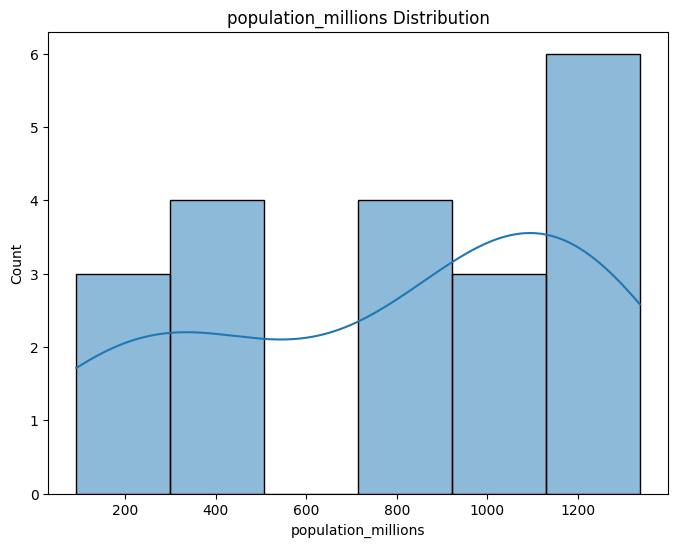

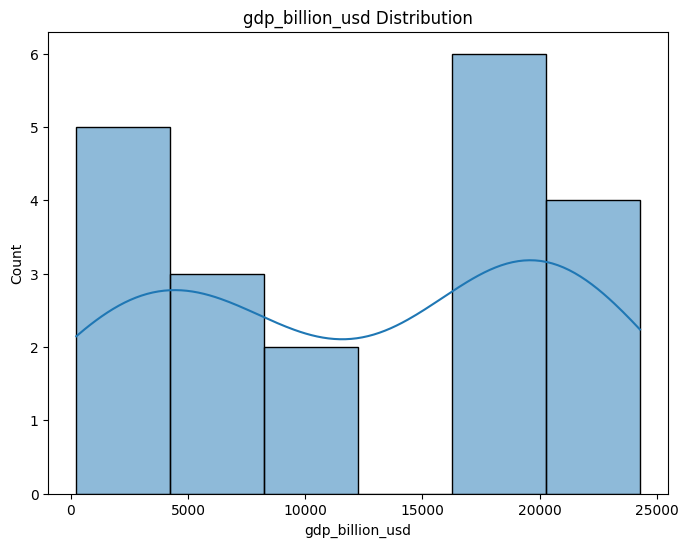

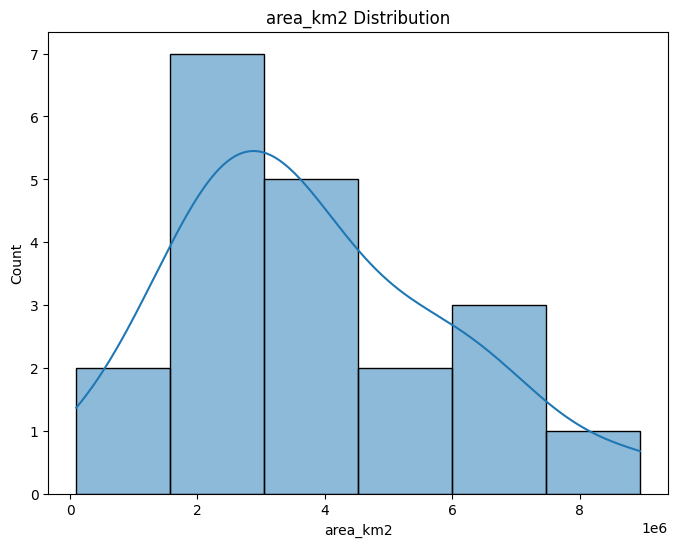

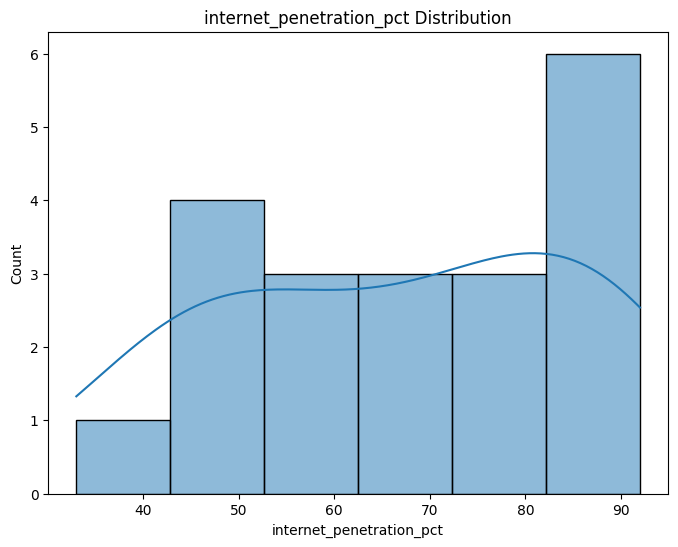

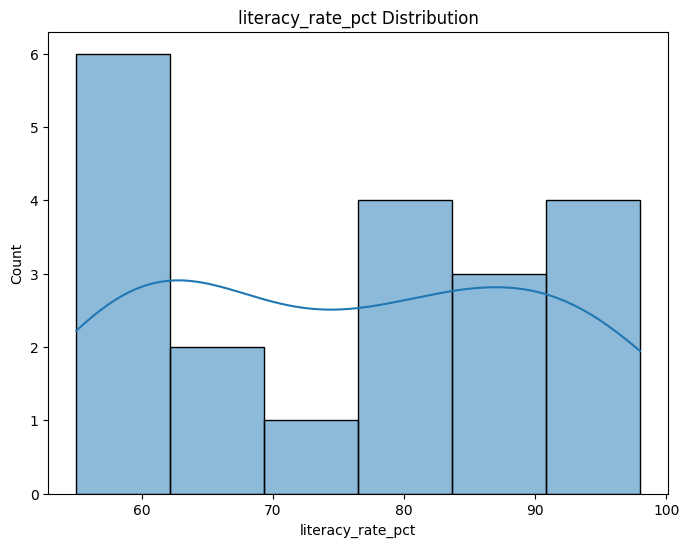

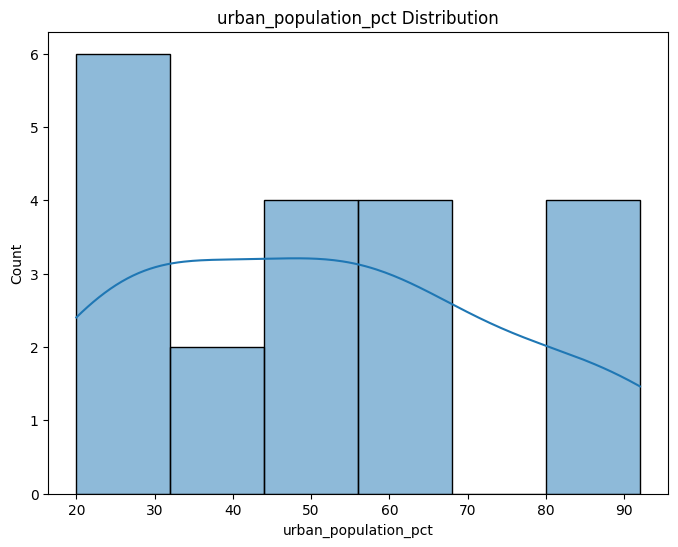

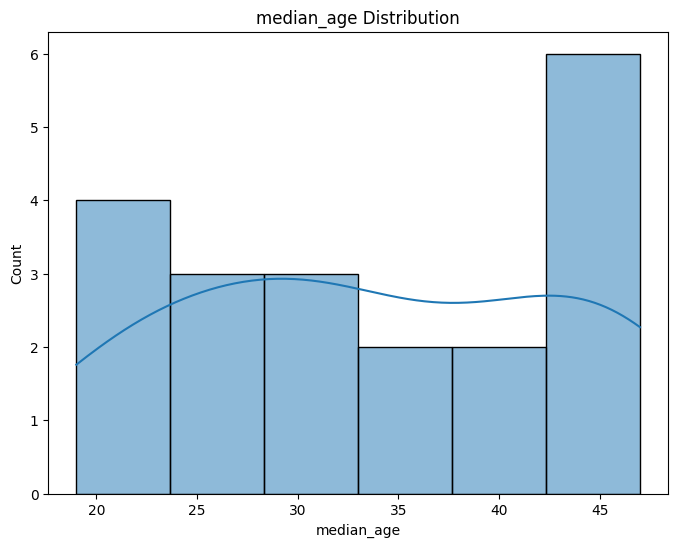

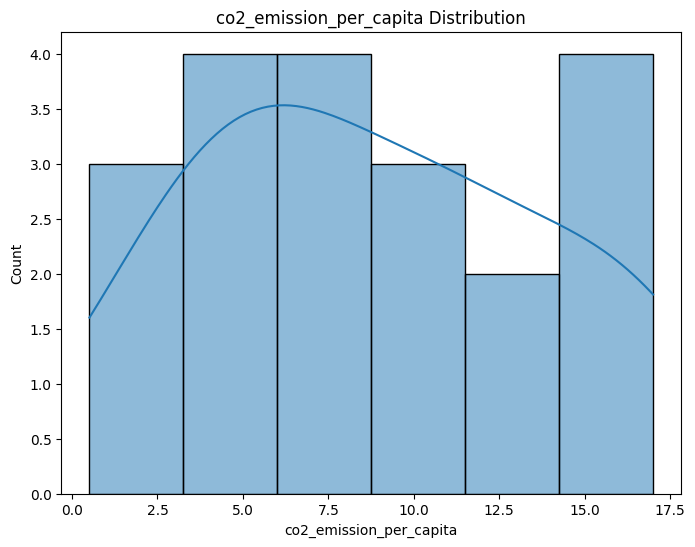

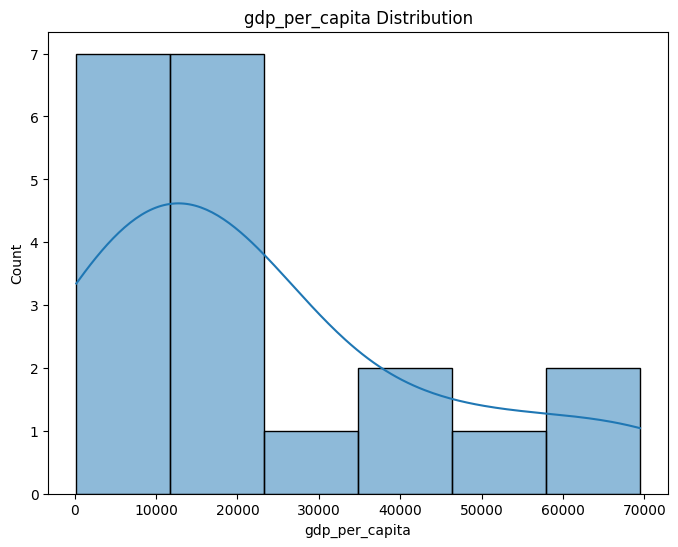

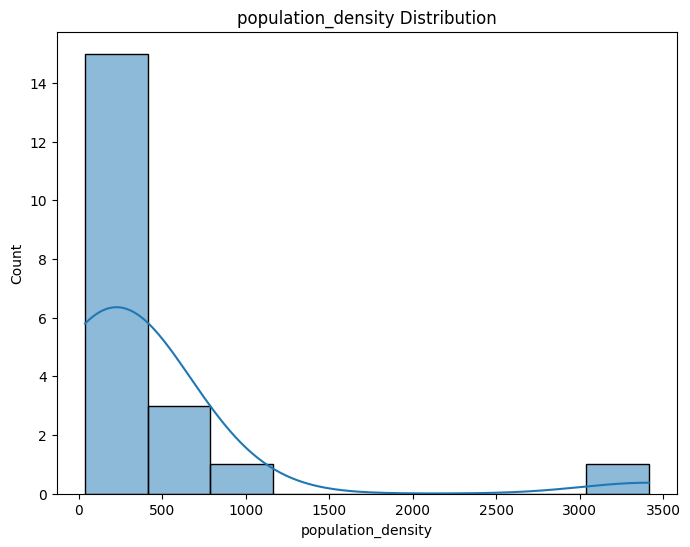

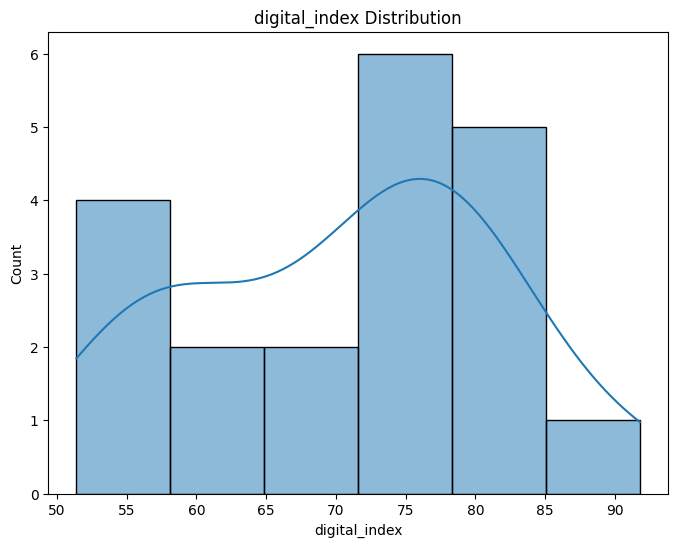

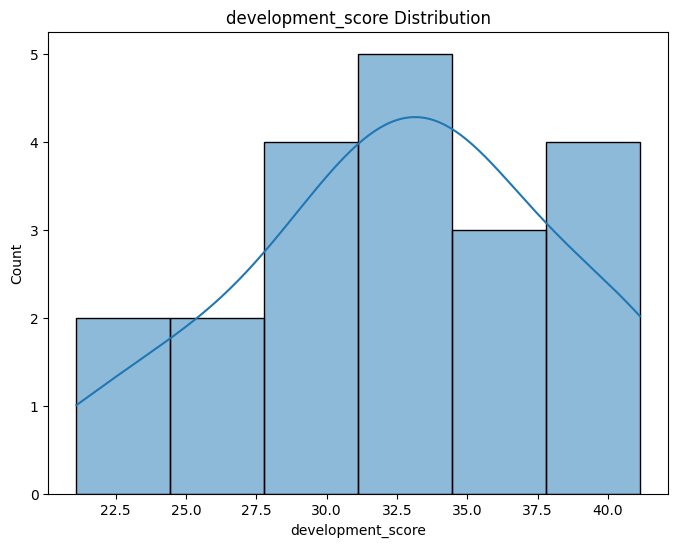

In [59]:
for cols in num_cols:
    plt.figure(figsize=(8,6))
    sea.histplot(data=df, x=cols, kde=True)
    plt.title(f"{cols} Distribution")
    plt.show()

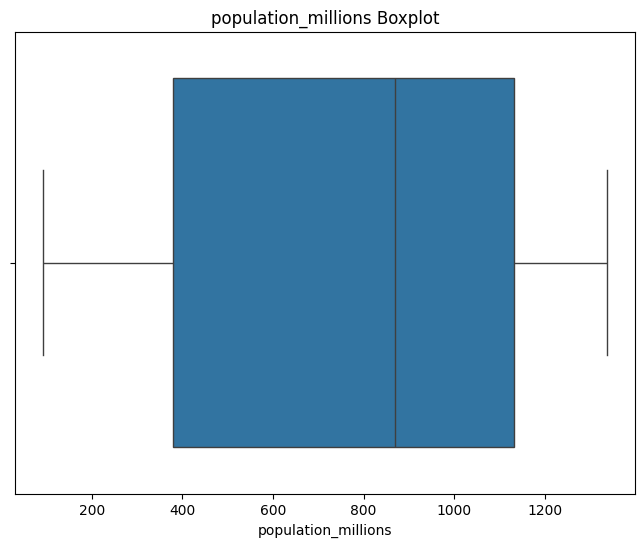

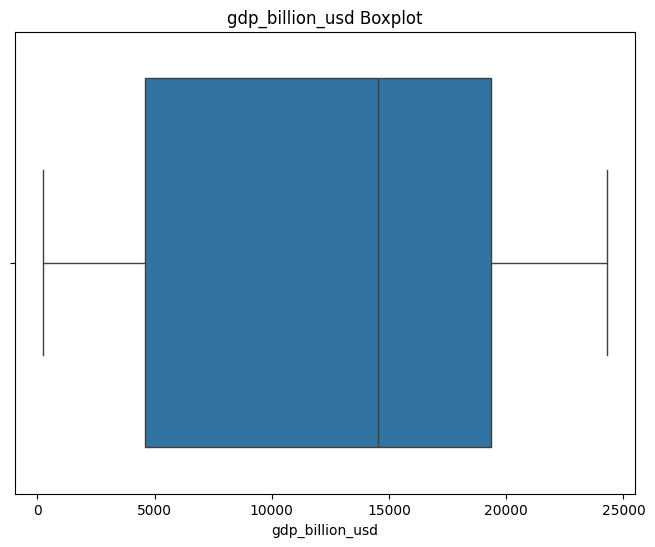

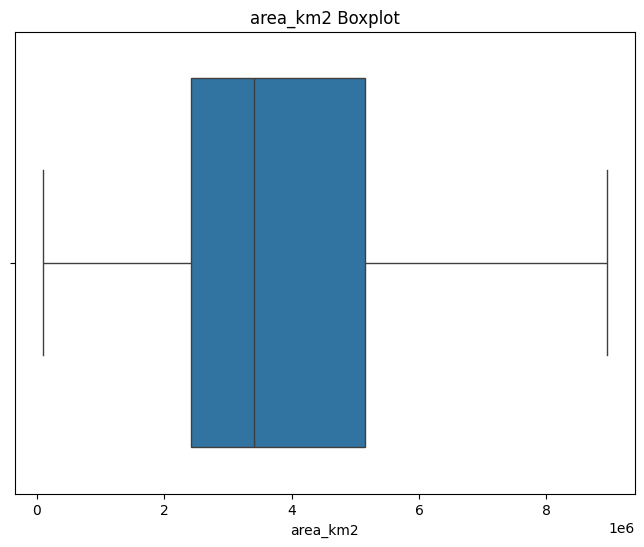

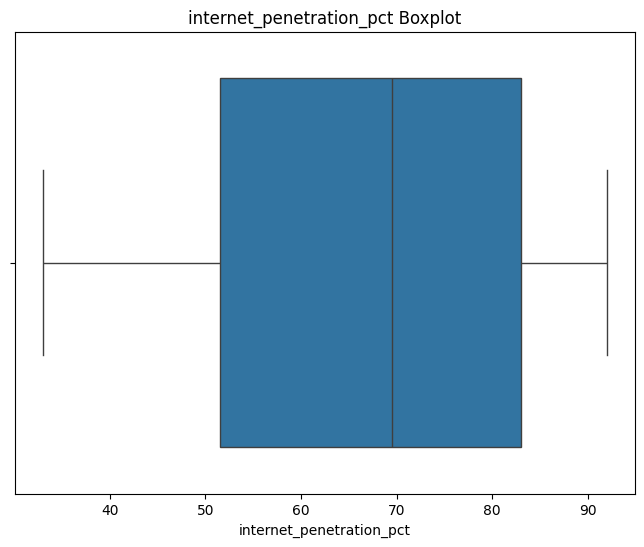

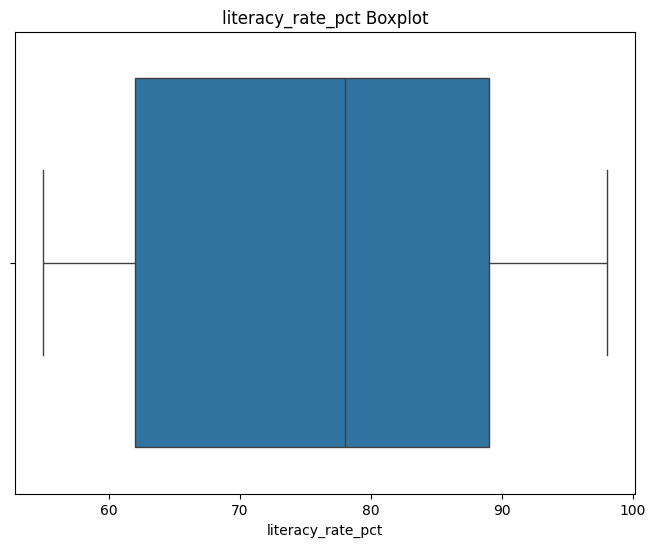

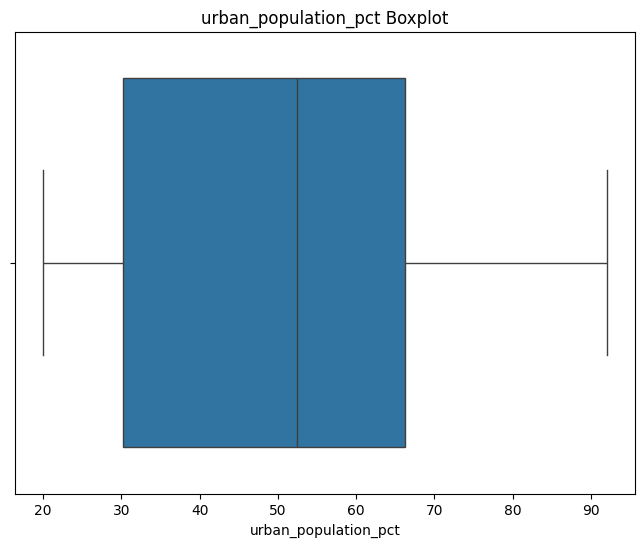

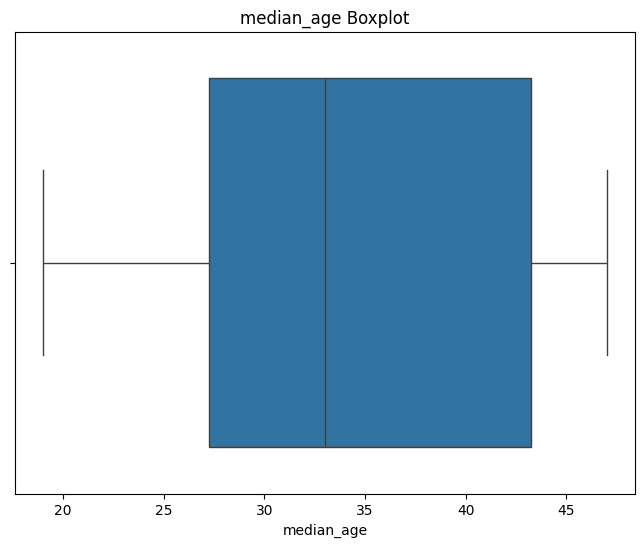

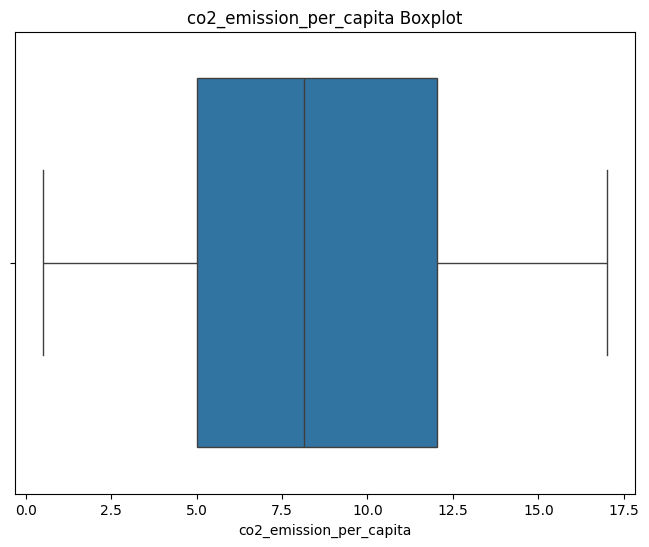

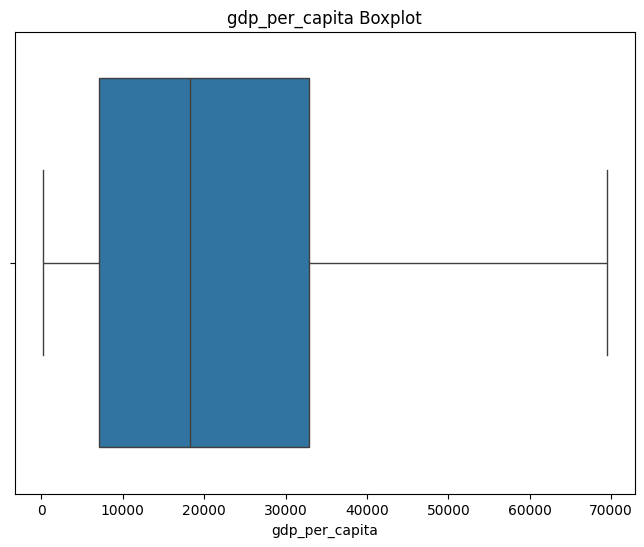

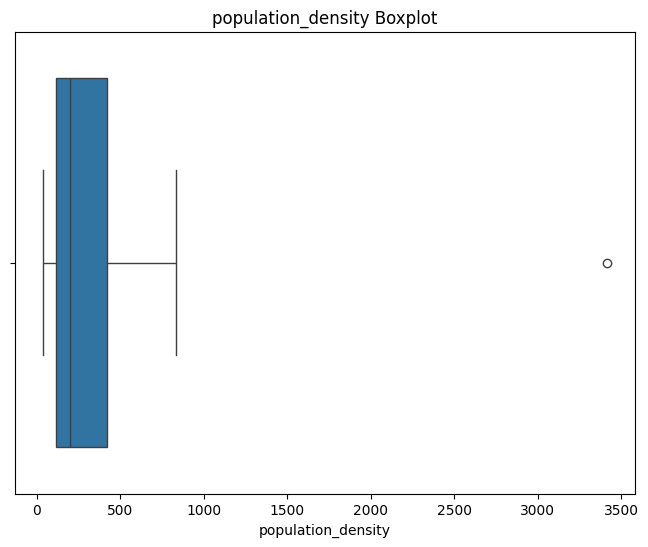

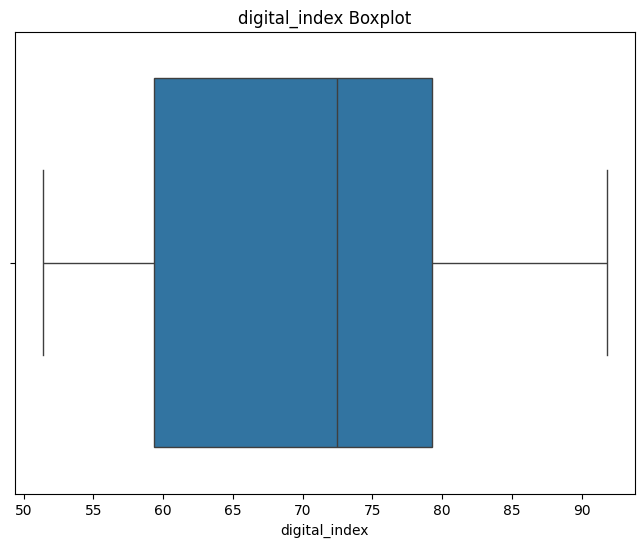

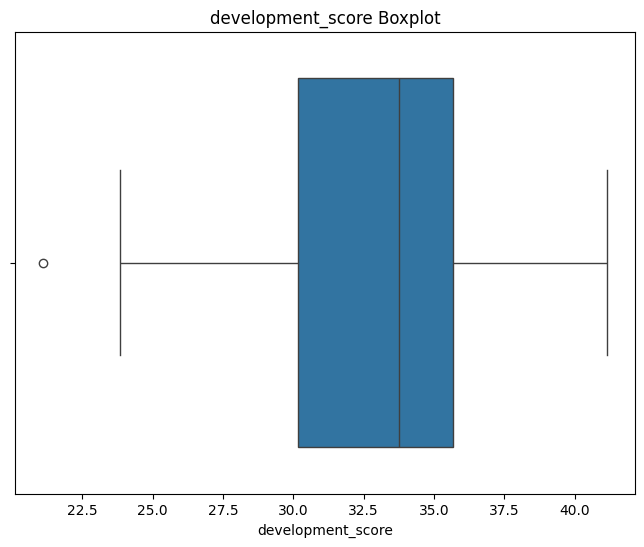

In [60]:
for cols in num_cols:
    plt.figure(figsize=(8,6))
    sea.boxplot(data=df, x=cols)
    plt.title(f"{cols} Boxplot")
    plt.show()

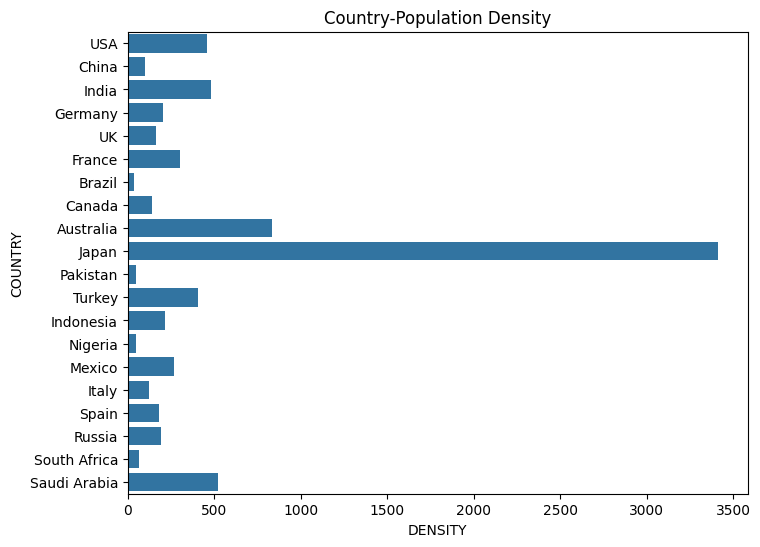

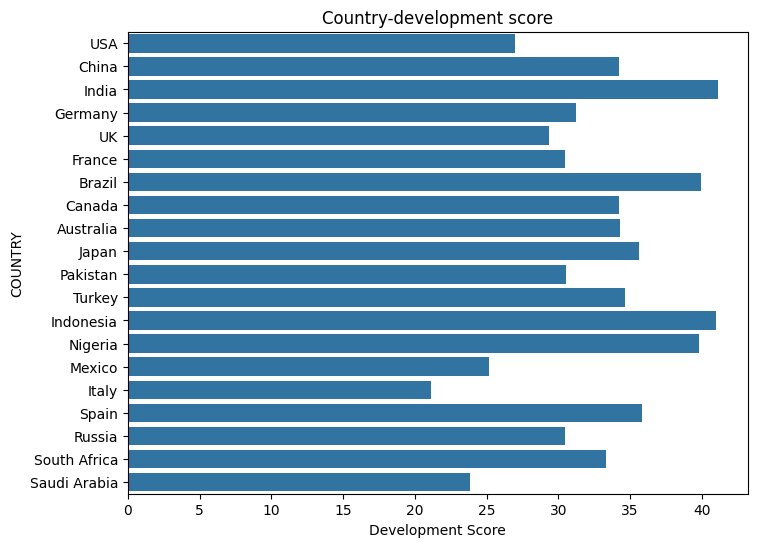

In [61]:
## Bivariate

plt.figure(figsize=(8,6))
sea.barplot(data=df, x='population_density', y='country', legend=False)
plt.title("Country-Population Density")
plt.xlabel("DENSITY")
plt.ylabel("COUNTRY")
plt.show()

plt.figure(figsize=(8,6))
sea.barplot(data=df, x='development_score', y='country', legend=False)
plt.title("Country-development score")
plt.xlabel("Development Score")
plt.ylabel("COUNTRY")
plt.show()


In [62]:
df.columns

Index(['country', 'population_millions', 'gdp_billion_usd', 'area_km2',
       'internet_penetration_pct', 'literacy_rate_pct', 'urban_population_pct',
       'median_age', 'co2_emission_per_capita', 'gdp_per_capita',
       'population_density', 'digital_index', 'development_score'],
      dtype='object')

In [63]:
df[['internet_penetration_pct', 'digital_index']].corr()

,internet_penetration_pct,digital_index
internet_penetration_pct,1.000000,0.862137
digital_index,0.862137,1.000000


I think that my target variable is development score. But as the dataset is tooo less we are only gonna be using it for EDA and Feature Engineering.

# Project 1: EDA
We answer some questions by plotting graphs and by using multiple parameters to answer them.

Top 10 Largest Countries


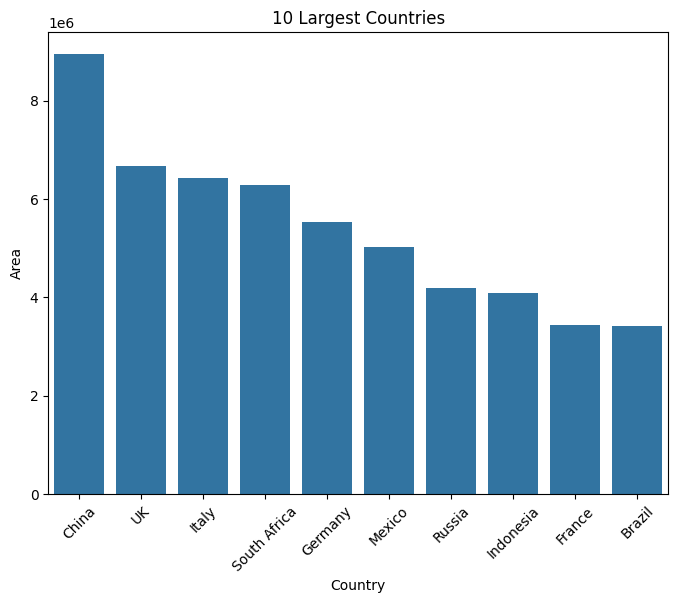

In [64]:
print("Top 10 Largest Countries")
largest_10_countries = df.sort_values(by='area_km2',ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=largest_10_countries.head(10), x='country', y='area_km2', legend=False)
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Area")
plt.show()


Top GDP Countries


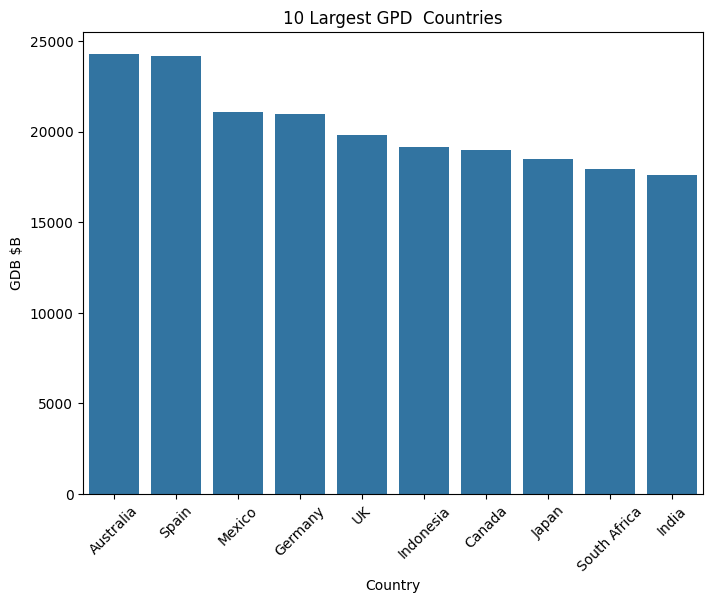

In [65]:
print("Top GDP Countries")
top_gdp_countries = df.sort_values(by='gdp_billion_usd', ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=top_gdp_countries.head(10), x='country', y='gdp_billion_usd', legend=False)
plt.title("10 Largest GPD  Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("GDB $B")
plt.show()

High Literacy rate Countries


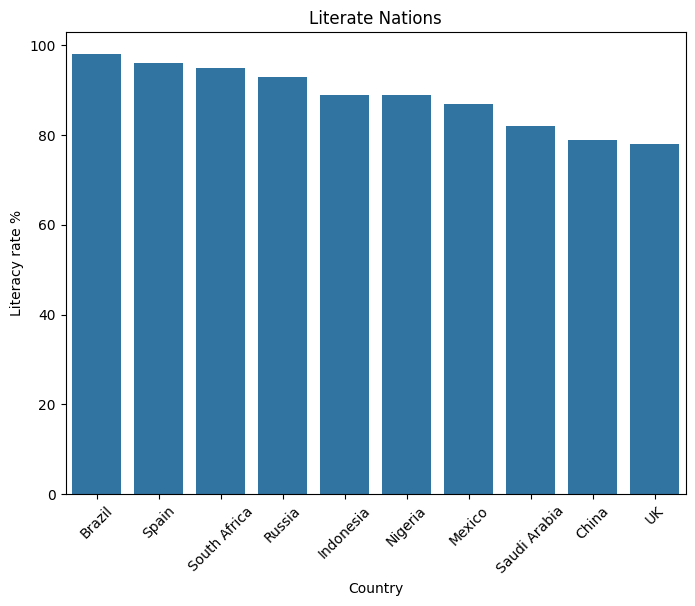

In [66]:
print("High Literacy rate Countries")
highly_literate_countries = df.sort_values(by='literacy_rate_pct',ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=highly_literate_countries.head(10), x='country', y="literacy_rate_pct", legend=False)
plt.title("Literate Nations")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Literacy rate %")
plt.show()

In [67]:
df.columns

Index(['country', 'population_millions', 'gdp_billion_usd', 'area_km2',
       'internet_penetration_pct', 'literacy_rate_pct', 'urban_population_pct',
       'median_age', 'co2_emission_per_capita', 'gdp_per_capita',
       'population_density', 'digital_index', 'development_score'],
      dtype='object')

Country Population Average Age, from highest to lowest (old to youth population


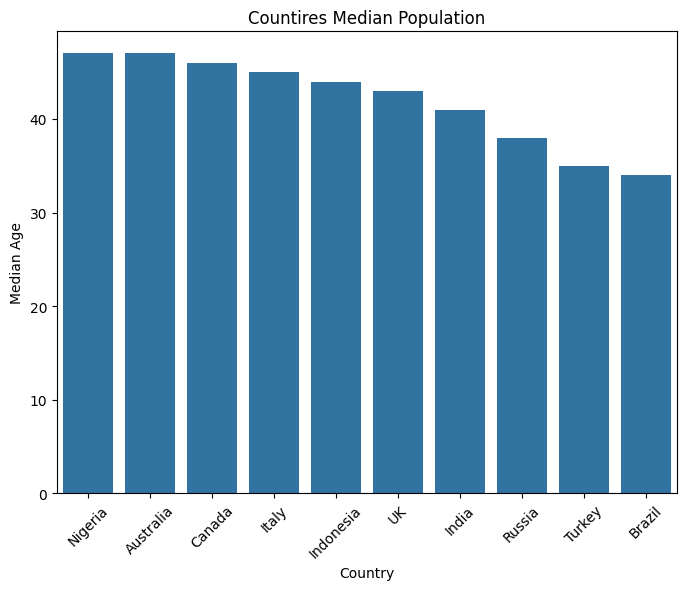

In [68]:
print("Country Population Average Age, from highest to lowest (old to youth population")
median_sorted = df.sort_values(by='median_age', ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=median_sorted.head(10), x='country', y='median_age', legend=False)
plt.title("Countires Median Population")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Median Age")
plt.show()

Dominant CO2 Emitting contries


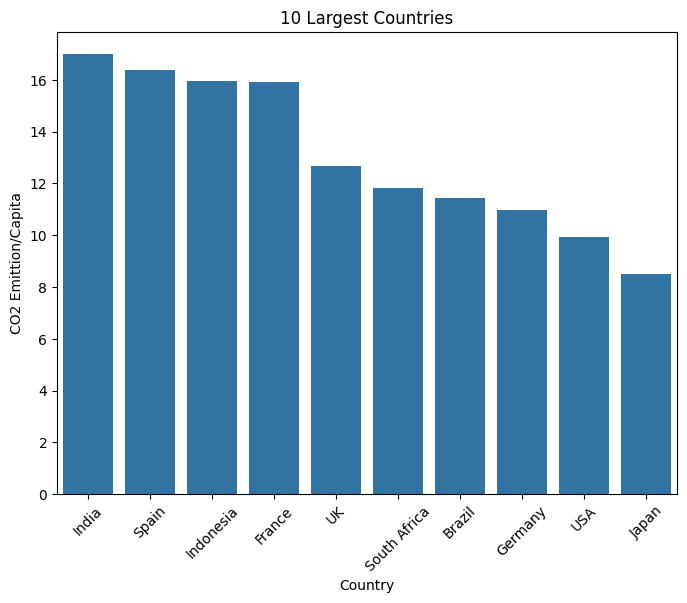

In [69]:
print("Dominant CO2 Emitting contries")
top_10_co2_emitters = df.sort_values(by='co2_emission_per_capita', ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=top_10_co2_emitters.head(10), x='country', y='co2_emission_per_capita', legend=False)
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("CO2 Emittion/Capita")
plt.show()

Least Internet Connected Country Population


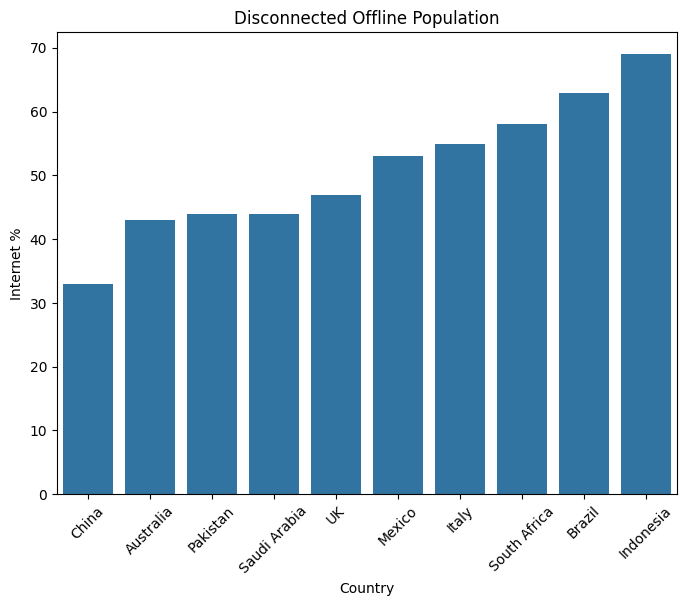

In [70]:
print("Least Internet Connected Country Population")
least_internet_connected = df.sort_values(by='internet_penetration_pct')
plt.figure(figsize=(8,6))
sea.barplot(data=least_internet_connected.head(10), x='country', y='internet_penetration_pct', legend=False)
plt.title("Disconnected Offline Population")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Internet %")
plt.show()

Influence of internet on Digital Index: 


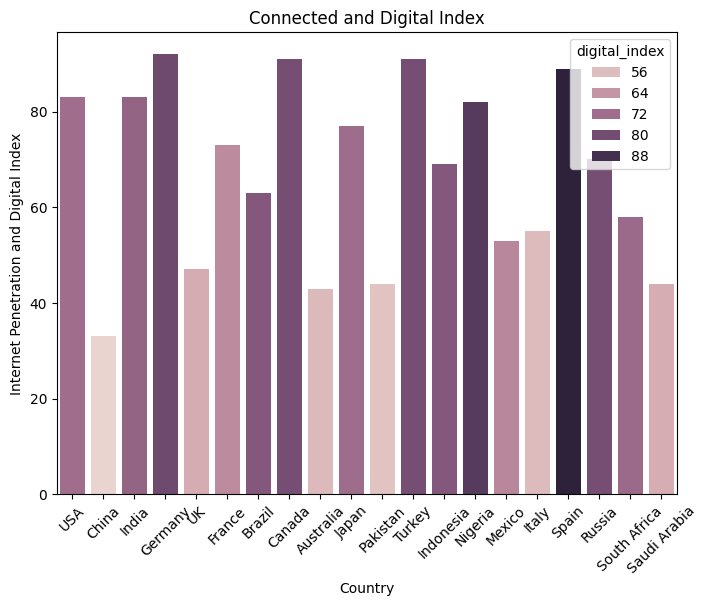

In [71]:
print("Influence of internet on Digital Index: ")
plt.figure(figsize=(8,6))
sea.barplot(data=df, x='country', y='internet_penetration_pct',hue='digital_index')
plt.title("Connected and Digital Index")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Internet Penetration and Digital Index")
plt.show()

GDP BIllion and GDP per Capita


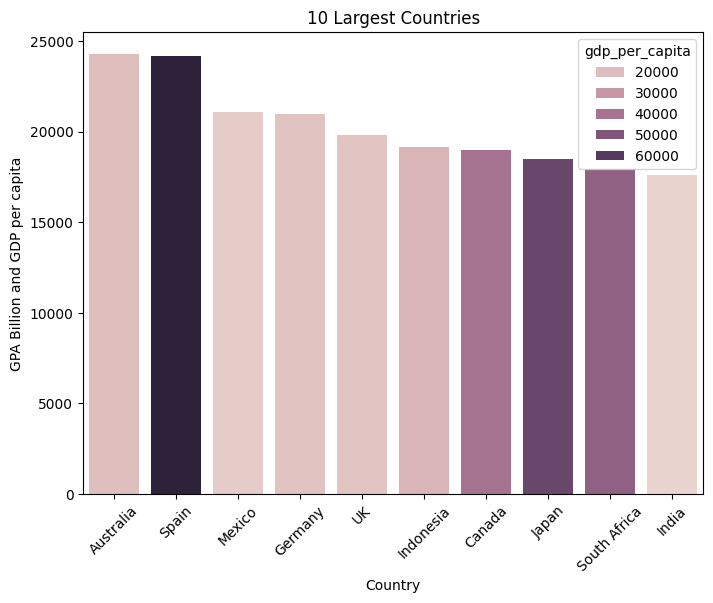

In [72]:
print("GDP BIllion and GDP per Capita")
top_gdp_countries
plt.figure(figsize=(8,6))
sea.barplot(data=top_gdp_countries.head(10), x='country', y='gdp_billion_usd',hue='gdp_per_capita')
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("GPA Billion and GDP per capita")
plt.show()

Urban Population and CO2 Emission


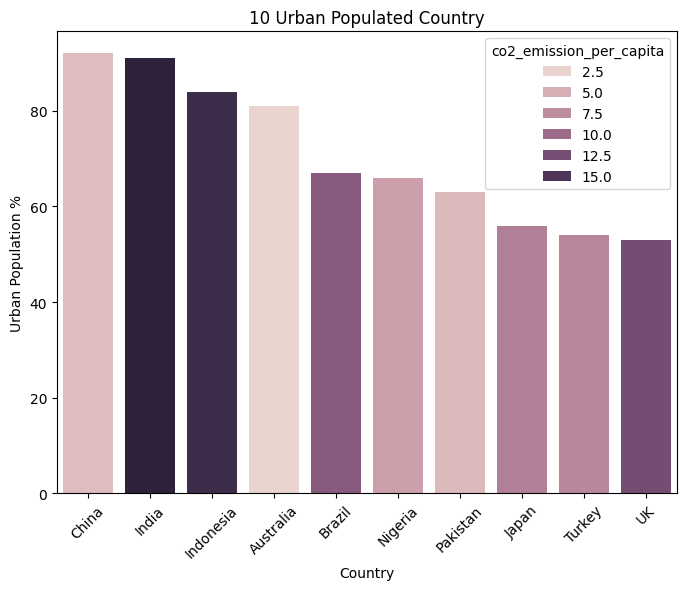

In [73]:
print("Urban Population and CO2 Emission")
df[['urban_population_pct','co2_emission_per_capita']].corr()
most_urban_populated_contries = df.sort_values(by='urban_population_pct',ascending=False)
plt.figure(figsize=(8,6))
sea.barplot(data=most_urban_populated_contries.head(10), x='country', y='urban_population_pct', hue='co2_emission_per_capita')
plt.title("10 Urban Populated Country")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Urban Population %")
plt.show()

population and area correlation


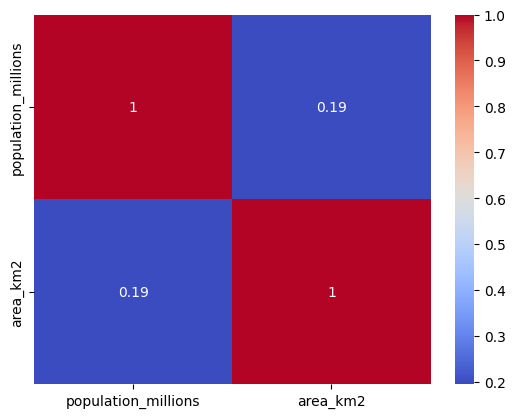

In [74]:

print("population and area correlation")
corr_pop_area = df[['population_millions','area_km2']].corr()
sea.heatmap(corr_pop_area,cmap='coolwarm',annot=True)
plt.show()

In [75]:
print("Population and Development score")
pop_development_corr = df[['population_millions', 'development_score']].corr()
display(pop_development_corr)

Population and Development score


,population_millions,development_score
population_millions,1.000000,-0.365902
development_score,-0.365902,1.000000


Internet + Digital Index == Development score


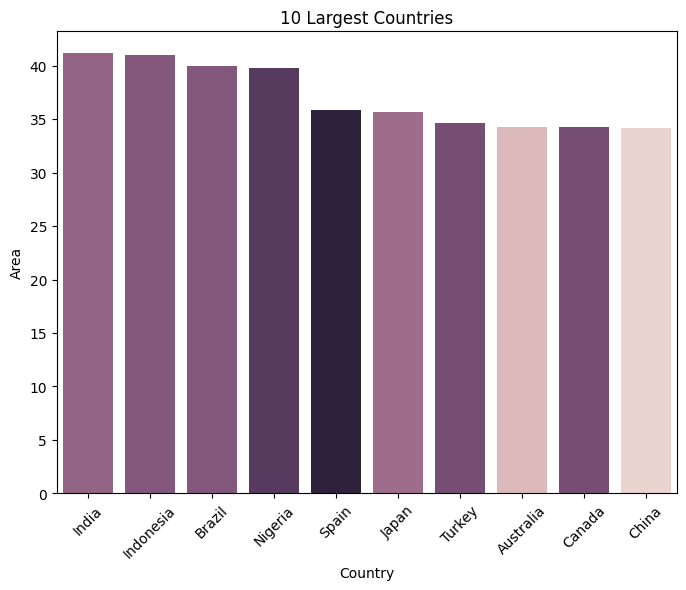

In [76]:
print("Internet + Digital Index == Development score")
techno_advanced_contry = df.sort_values(by='development_score', ascending=False)
techno_advanced_contry
plt.figure(figsize=(8,6))
sea.barplot(data=techno_advanced_contry.head(10), x='country', y='development_score',hue='digital_index', legend=False)
plt.title("10 Largest Countries")
plt.xlabel("Country")
plt.xticks(rotation=45)
plt.ylabel("Area")
plt.show()


I am thinking it is a toy dataset cause australia was never among top GDP's and thisis

In [77]:
df.columns

Index(['country', 'population_millions', 'gdp_billion_usd', 'area_km2',
       'internet_penetration_pct', 'literacy_rate_pct', 'urban_population_pct',
       'median_age', 'co2_emission_per_capita', 'gdp_per_capita',
       'population_density', 'digital_index', 'development_score'],
      dtype='object')

In [31]:
!pip install ydata-profiling


In [32]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title='World-Dataset-Report')

profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:00<00:00, 46405.07it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [33]:
profile.to_file("world_dataset.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

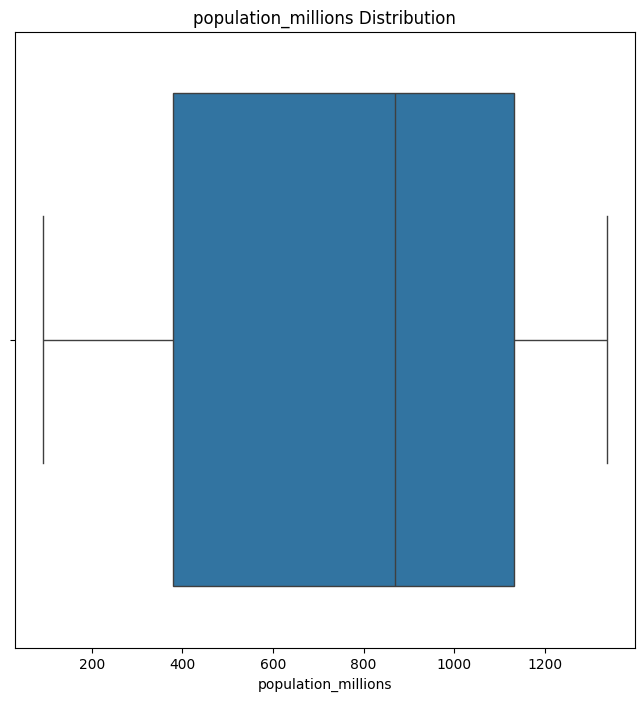

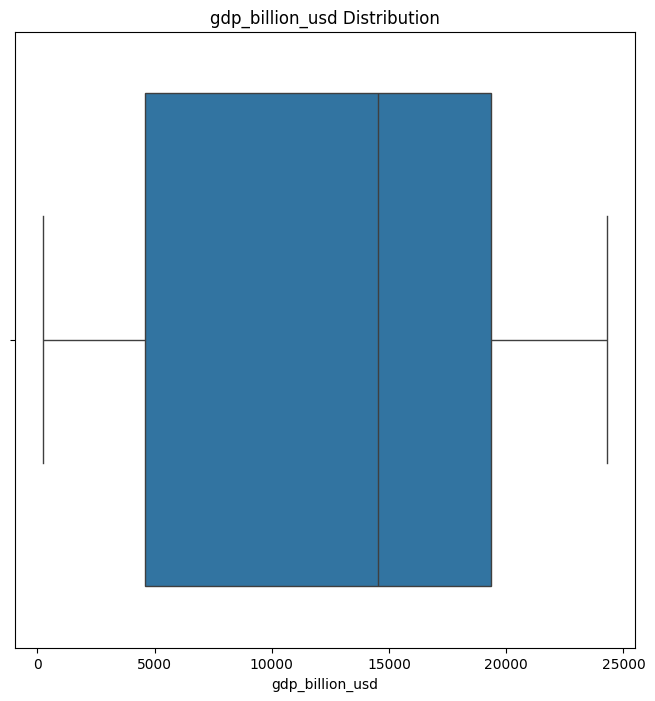

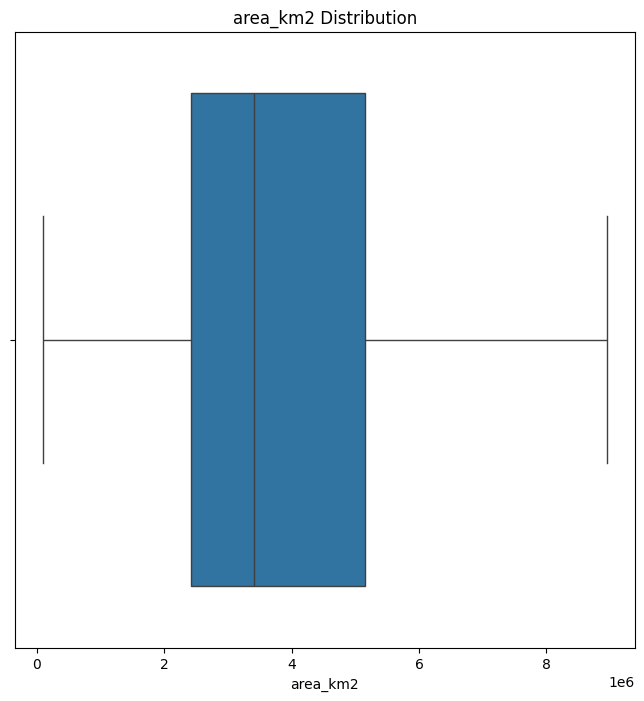

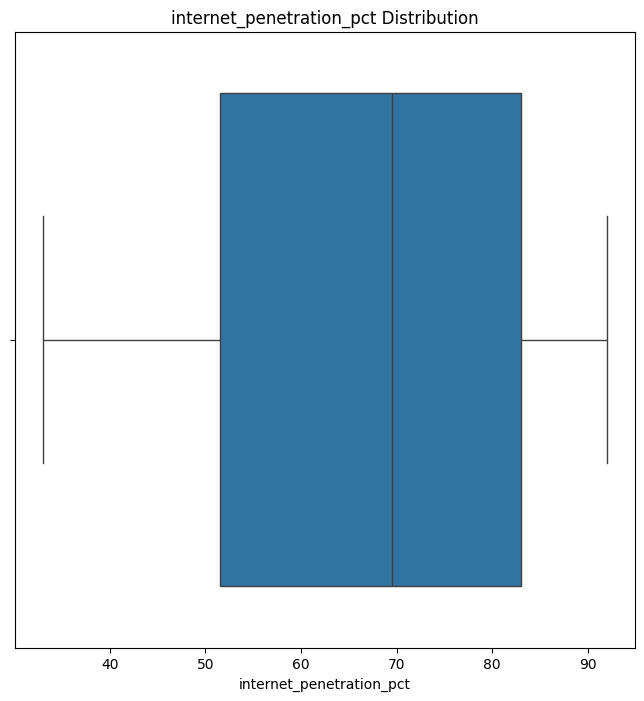

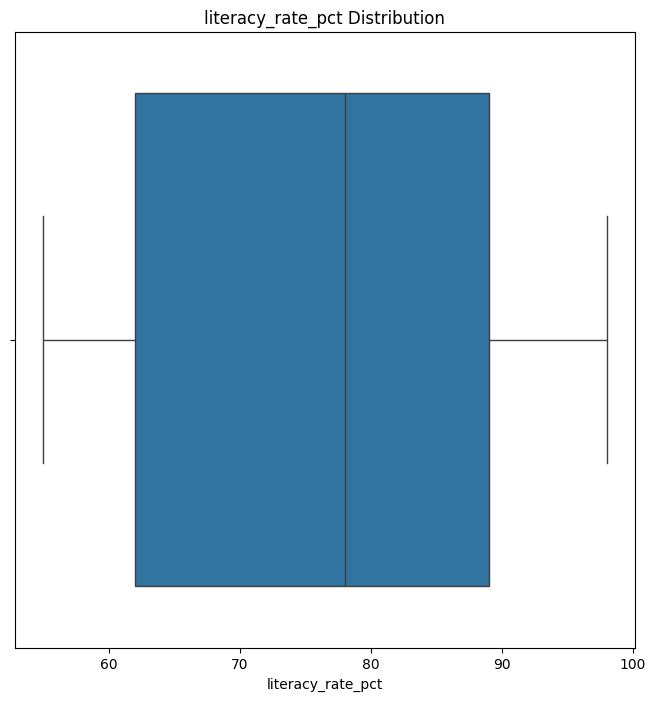

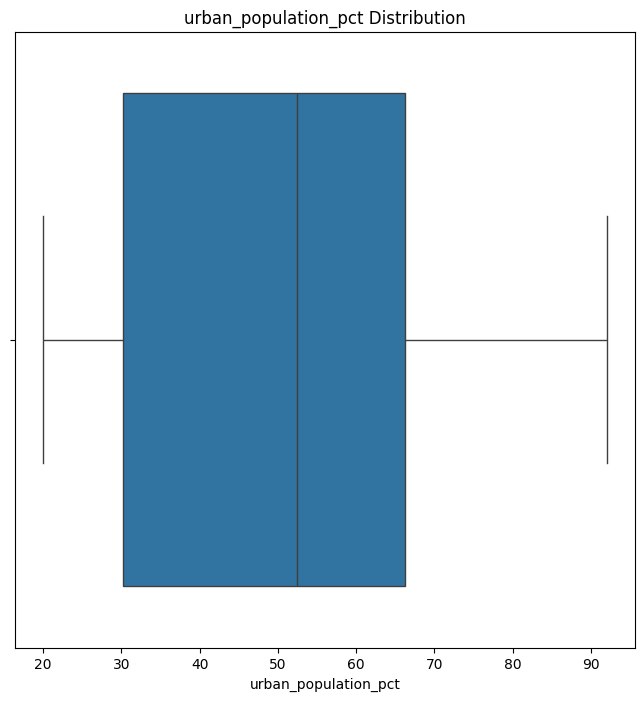

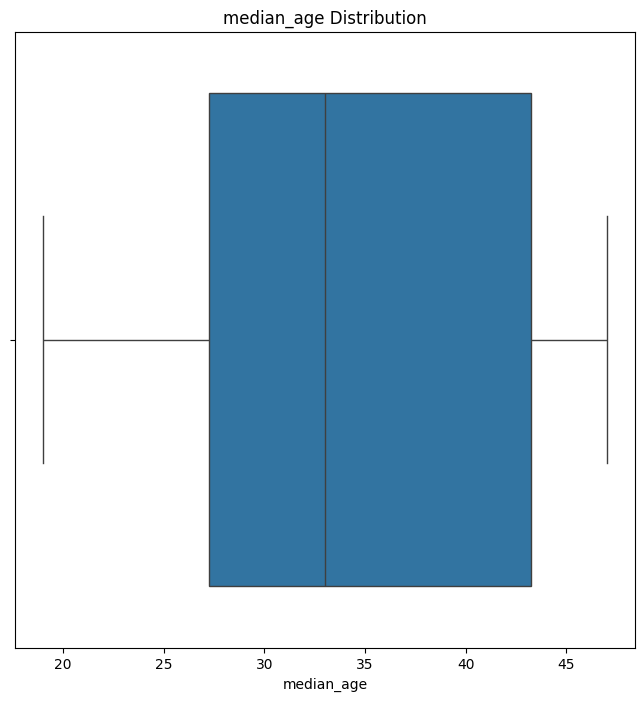

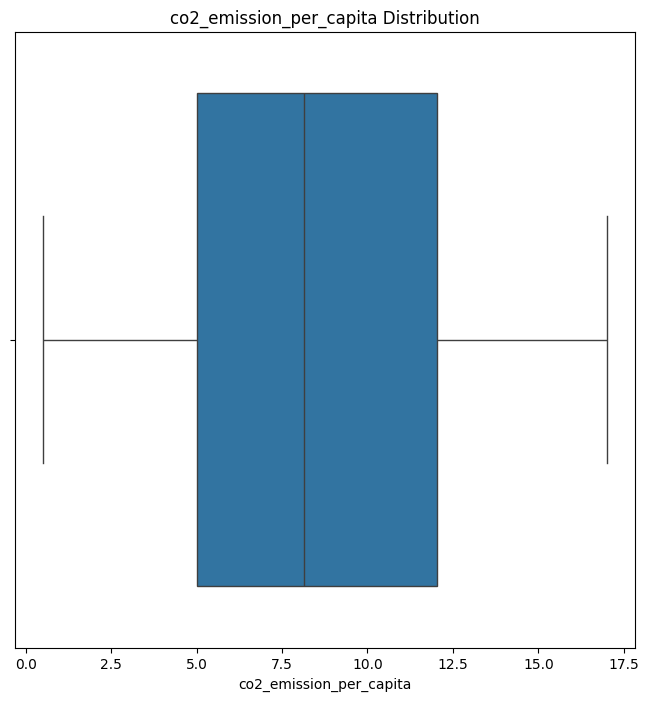

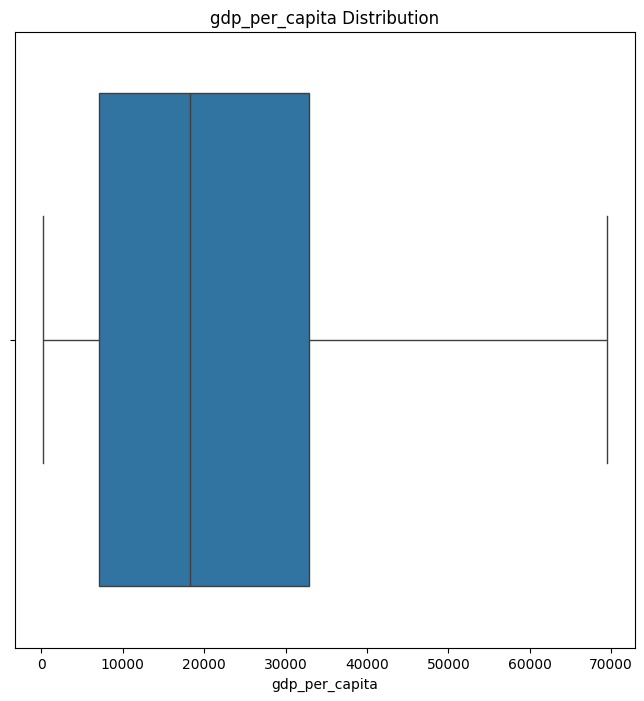

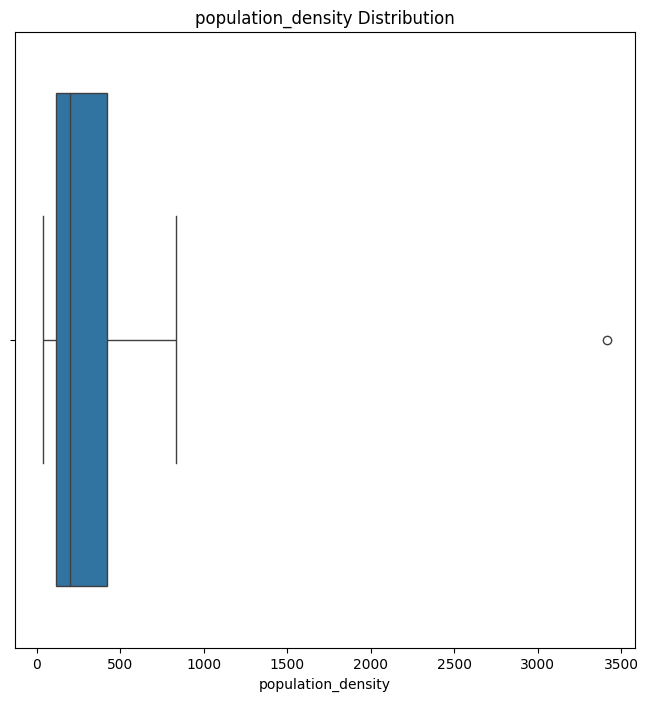

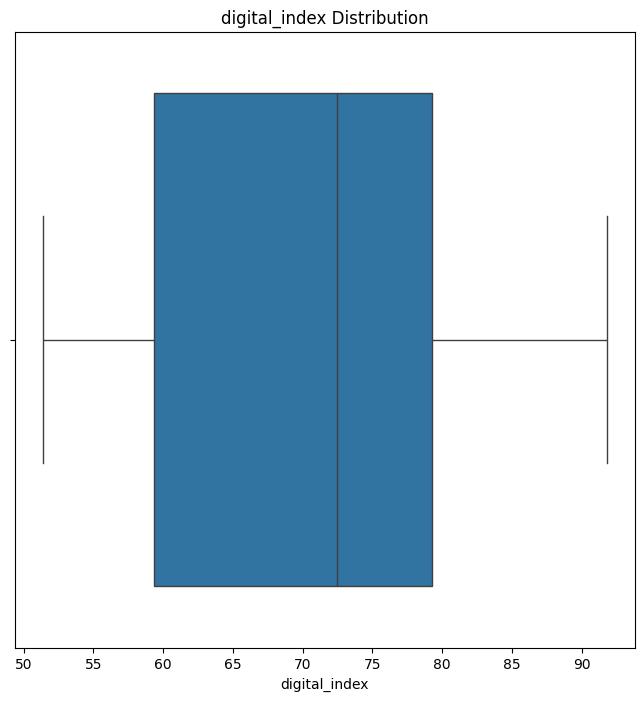

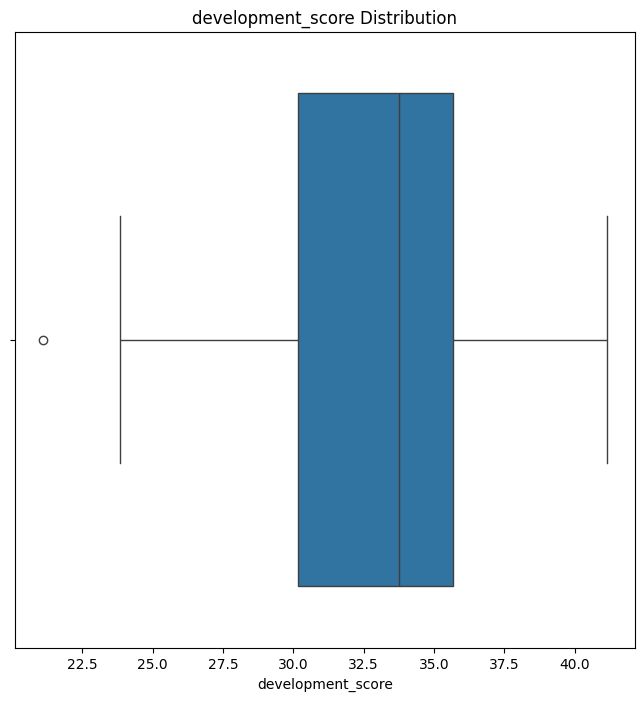

In [78]:
for col in num_cols:
    plt.figure(figsize=(8,8))
    sea.boxplot(x=col, data=df)
    plt.title(f"{col} Distribution")
    plt.show()

In [79]:
## Fixing Outliers.

Q1 = df['population_density'].quantile(0.25)
Q3 = df['population_density'].quantile(0.75)

IQR = Q3 - Q1

up_bound = Q3 + 1.5 * IQR
low_bound = Q1 - 1.5*IQR

df['population_density'] = df['population_density'].clip(lower=low_bound, upper=up_bound)
up_bound

np.float64(877.7922265329026)

In [80]:

Q1 = df['development_score'].quantile(0.25)
Q3 = df['development_score'].quantile(0.75)

IQR = Q3 - Q1

up_bound = Q3 + 1.5 * IQR
low_bound = Q1 - 1.5*IQR

df['development_score'] = df['development_score'].clip(lower=low_bound, upper=up_bound)

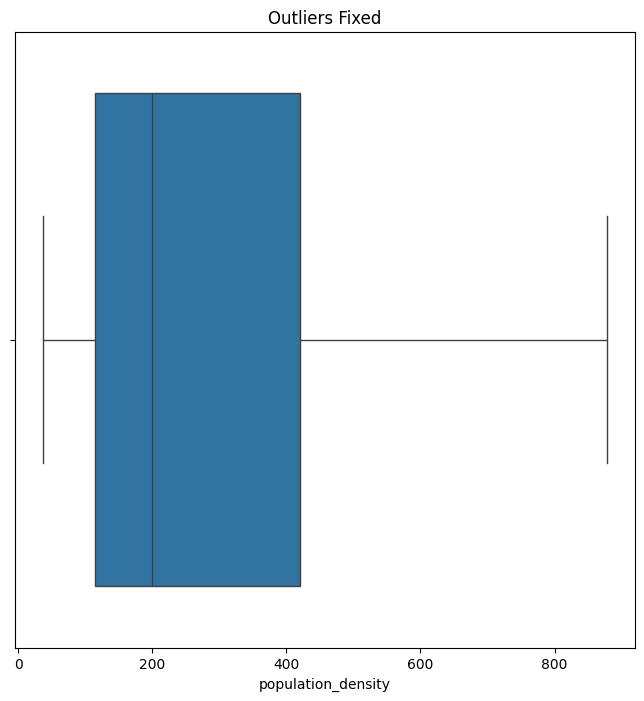

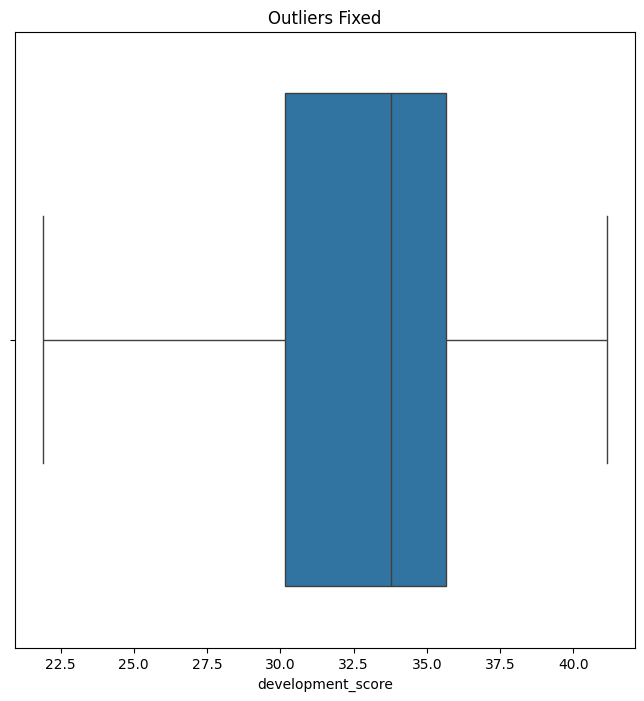

In [81]:
plt.figure(figsize=(8,8))
sea.boxplot(data=df, x='population_density')
plt.title("Outliers Fixed")
plt.show()

plt.figure(figsize=(8,8))
sea.boxplot(data=df, x='development_score')
plt.title("Outliers Fixed")
plt.show()

In [82]:
df.describe()

,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
count,20.000000,20.000000,2.000000e+01,20.000000,20.000000,20.000000,20.000000,20.00000,20.000000,20.000000,20.00000,20.000000
mean,793.200000,12505.300000,3.787281e+06,67.000000,75.850000,51.550000,33.800000,8.80450,23616.862639,283.249576,70.54000,32.692681
std,428.944678,8479.400327,2.136956e+06,18.881904,14.776493,23.444167,9.589468,5.07259,21583.261888,245.115355,11.17631,5.550168
min,92.000000,239.000000,9.814800e+04,33.000000,55.000000,20.000000,19.000000,0.51000,211.879433,36.888928,51.40000,21.902662
25%,379.500000,4589.500000,2.427644e+06,51.500000,62.000000,30.250000,27.250000,5.02500,7146.051566,114.478915,59.35000,30.161188
50%,870.500000,14531.000000,3.415508e+06,69.500000,78.000000,52.500000,33.000000,8.14000,18254.891870,199.394538,72.50000,33.768404
75%,1132.000000,19330.750000,5.153351e+06,83.000000,89.000000,66.250000,43.250000,12.03750,32882.309840,419.804240,79.25000,35.666872
max,1337.000000,24283.000000,8.946786e+06,92.000000,98.000000,92.000000,47.000000,17.00000,69448.275862,877.792227,91.80000,41.138137


## Scaling Feaures.

In [83]:
df = df.copy()

In [84]:
df.sample()

,country,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
3,Germany,1135,20989,5529720,92,63,31,25,10.98,18492.511013,205.254516,80.4,31.244626


In [85]:
numerical_columns.sample()

,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index,development_score
10,92,2797,1855665,44,71,63,32,4.32,30402.173913,49.577914,54.8,30.560109


In [86]:
## Train test split:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(numerical_columns.drop('development_score', axis=1), numerical_columns['development_score'],
                                                    test_size= 0.3, random_state=0)

X_train.shape, X_test.shape

((14, 11), (6, 11))

## StandardScaler

In [87]:
from sklearn.preprocessing  import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

### StandardScaler return np array so transform it back okay

In [88]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [89]:
X_train_scaled

,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index
0,-1.618573,-0.558502,-0.116225,-0.806015,1.647214,0.810391,-0.021723,0.198842,1.911909,-0.510279,0.321381
1,-1.597061,-1.252189,-0.528044,0.485551,1.059257,0.765009,1.296115,-0.994208,-0.128513,-0.494480,1.165007
2,0.709577,0.802037,1.756968,-1.893650,0.340642,0.175044,0.890626,0.478356,-0.330708,-0.356034,-1.582185
3,1.185247,0.532331,-0.532043,0.553529,-0.769944,1.899556,0.687882,1.464610,-0.525984,0.026499,0.018541
4,0.587672,-0.836663,-0.098383,-0.126243,-1.161916,0.129663,-0.629955,1.216910,-0.851165,-0.187989,-0.889979
5,1.276078,0.958028,0.811515,-1.485787,0.928600,-1.231794,-1.542304,-1.798663,-0.428977,-0.234304,-0.803453
6,-1.119001,0.638082,-2.025242,0.145665,-0.508630,0.311190,-1.238188,-0.469266,1.297856,3.558144,-0.197773
7,-0.793921,0.700698,-0.116399,1.097346,-0.704616,-0.324156,1.194743,-1.110104,0.647110,-0.388554,0.580958
8,-1.087927,1.334955,-0.987856,0.961392,1.516557,-1.141030,-1.440932,1.321444,1.923906,-0.334135,1.922107
9,0.776505,-1.597256,-0.484490,1.097346,-0.704616,0.220426,0.079650,-0.628339,-1.111255,-0.065040,0.580958


Observing the statistical summary ofmy dataset before and after claing

In [90]:
print("Statistical summary before sclaing: ")
display(np.round(X_train.describe(), 1))

print("Statistical Summary after scaling: ")
display(np.round(X_train_scaled.describe(), 1))

Statistical summary before sclaing: 


,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index
count,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0
mean,803.1,13273.8,3617635.7,74.9,72.8,49.1,34.2,10.6,25561.2,460.4,74.0
std,434.2,8468.8,1803411.5,15.3,15.9,22.9,10.2,4.6,23672.6,861.2,9.6
min,126.0,239.0,98148.0,47.0,55.0,20.0,19.0,2.6,211.9,36.9,56.6
25%,378.8,5437.2,2694783.2,64.5,61.2,27.2,25.8,7.0,7999.4,144.7,67.9
50%,962.5,18049.5,3415508.0,79.5,64.0,52.5,34.5,10.5,18254.9,209.8,75.6
75%,1130.2,19656.2,4792550.8,87.5,88.5,63.5,43.8,15.1,35899.4,380.9,79.4
max,1337.0,24168.0,6670913.0,92.0,98.0,91.0,47.0,17.0,69448.3,3413.2,91.8


Statistical Summary after scaling: 


,population_millions,gdp_billion_usd,area_km2,internet_penetration_pct,literacy_rate_pct,urban_population_pct,median_age,co2_emission_per_capita,gdp_per_capita,population_density,digital_index
count,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0,14.0
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
min,-1.6,-1.6,-2.0,-1.9,-1.2,-1.3,-1.5,-1.8,-1.1,-0.5,-1.9
25%,-1.0,-1.0,-0.5,-0.7,-0.8,-1.0,-0.9,-0.8,-0.8,-0.4,-0.7
50%,0.4,0.6,-0.1,0.3,-0.6,0.2,0.0,-0.0,-0.3,-0.3,0.2
75%,0.8,0.8,0.7,0.9,1.0,0.7,1.0,1.0,0.5,-0.1,0.6
max,1.3,1.3,1.8,1.2,1.6,1.9,1.3,1.5,1.9,3.6,1.9


### Effect of scaling.

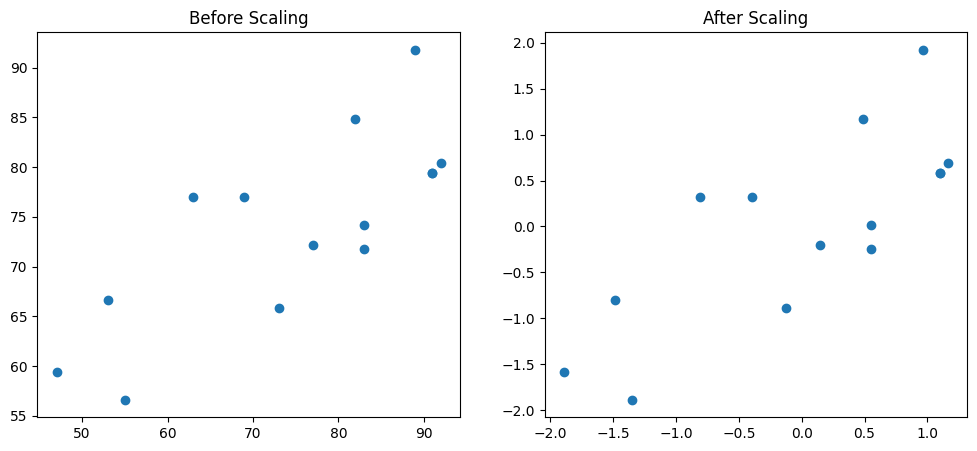

In [91]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(X_train['internet_penetration_pct'], X_train['digital_index'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['internet_penetration_pct'], X_train_scaled['digital_index'])
ax2.set_title("After Scaling")
plt.show()

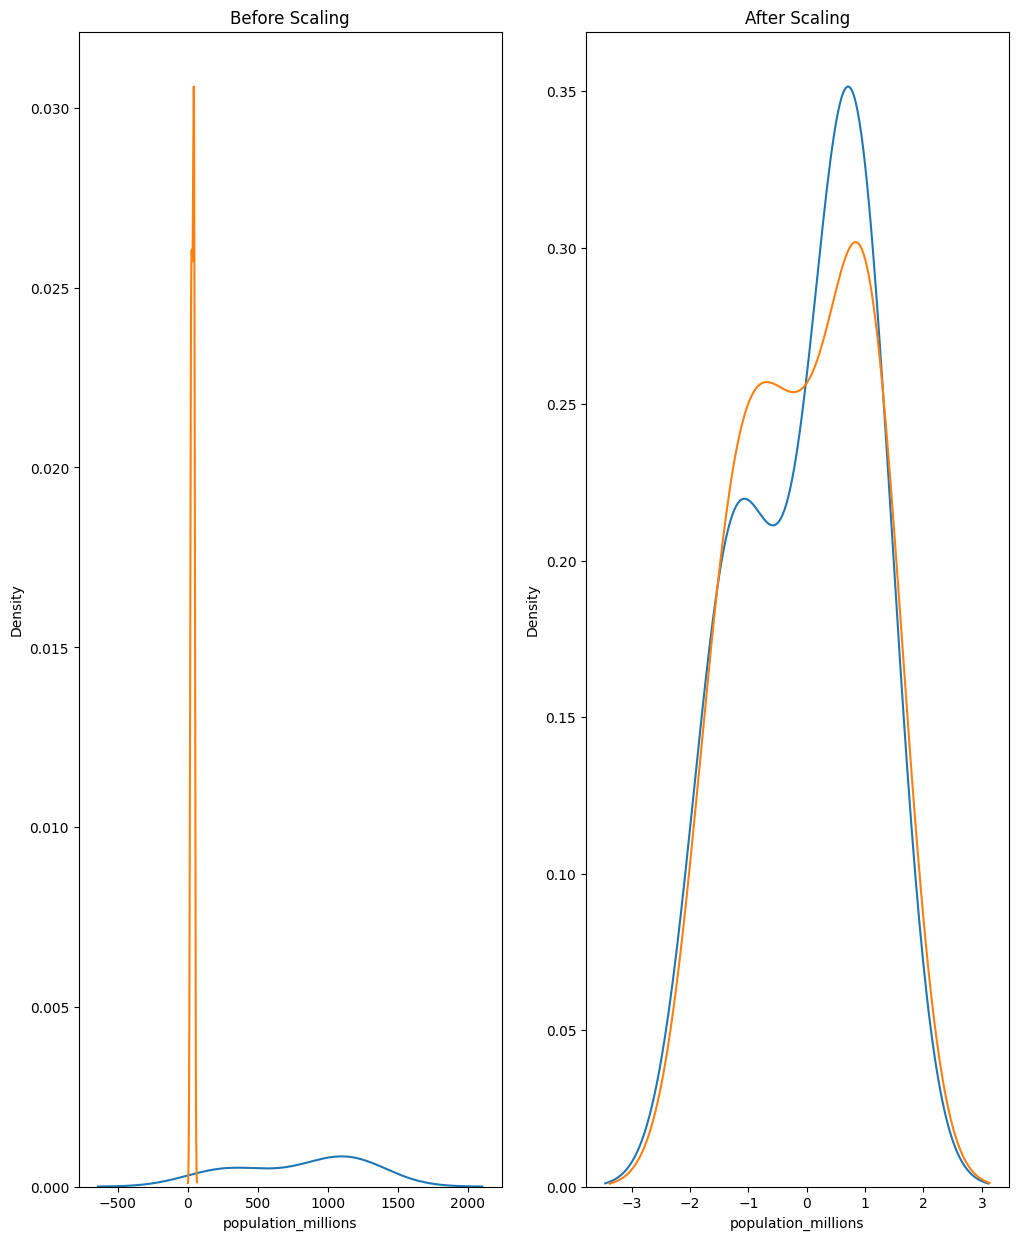

In [92]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize=(12,15))
ax1.set_title("Before Scaling")

sea.kdeplot(X_train['population_millions'], ax=ax1,legend=True)
sea.kdeplot(X_train['median_age'], ax=ax1,legend=True)

ax2.set_title("After Scaling")
sea.kdeplot(X_train_scaled['population_millions'], ax=ax2,legend=True)
sea.kdeplot(X_train_scaled['median_age'], ax=ax2,legend=True)

plt.show()

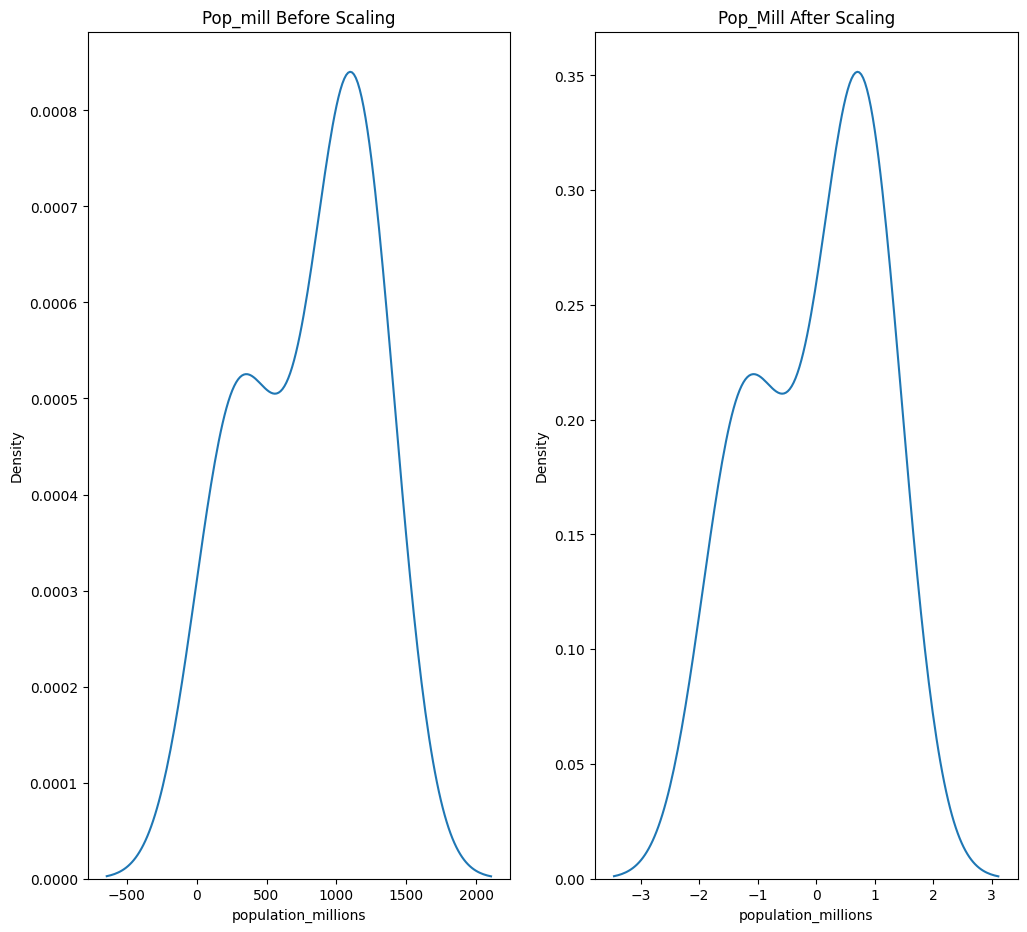

In [93]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize=(12,11))
ax1.set_title("Pop_mill Before Scaling")
sea.kdeplot(X_train['population_millions'], ax=ax1,legend=True)

ax2.set_title("Pop_Mill After Scaling")
sea.kdeplot(X_train_scaled['population_millions'], ax=ax2,legend=True)
plt.show()

6     39.958730
13    39.771481
4     29.320864
2     41.138137
5     30.447245
14    25.168781
9     35.618358
7     34.236136
16    35.812414
11    34.630594
3     31.244626
0     26.965508
15    21.105904
12    40.994064
Name: development_score, dtype: float64

## Training The Model

In [123]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score

# 1. Load dataset
df = pd.read_csv('world_feature_engineering_dataset.csv')

# 2. Separate features (X) and continuous target (y)
X = df.drop(columns=['country', 'development_score'])
y = df['development_score']

# 3. Fit Linear Regression
model = LinearRegression()
model_scaled = LinearRegression()

model.fit(X_train, y_train)
model_scaled.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test)
y_pred_scaled = model_scaled.predict(X_test_scaled)

# 4. Generate fitted values (predictions)


In [126]:
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 1. R² Score (Higher is better, max 1.0)
print("Actual R2: ", r2_score(y_test, y_pred))
print("Scaled R2: ", r2_score(y_test, y_pred_scaled))

# 2. Root Mean Squared Error (Lower is better)
print("Actual RMSE: ", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Scaled RMSE: ", np.sqrt(mean_squared_error(y_test, y_pred_scaled)))

# 3. Mean Absolute Error (Lower is better)
print("Actual MAE: ", mean_absolute_error(y_test, y_pred))
print("Scaled MAE: ", mean_absolute_error(y_test, y_pred_scaled))

Actual R2:  1.0
Scaled R2:  1.0
Actual RMSE:  3.299149470072163e-13
Scaled RMSE:  3.134317757718948e-14
Actual MAE:  2.9902006796570885e-13
Scaled MAE:  2.4276876805136755e-14


## Normalisation.
MinMax, Mean, MaxAbsoloute , RobustScaling